# PS05-AI · Học mẫu trước khi làm Bài 27–28
### Mô phỏng đúng phép thử → nhận diện biến cố → đối chiếu xác suất

**Nguyễn Bích Vân — IAI-UET-VNU**

Đây là notebook học cú pháp, **chạy được ngay từ đầu đến cuối**. Các ví dụ dùng số liệu riêng, không phải lời giải của hai bài được giao.

Sau khi chạy mẫu, mở `PS05_AI_27_28_Student.ipynb` để làm bài. Chỉ cần sửa các ô cấu hình được đánh dấu; không phải tự dựng toàn bộ chương trình.

| Phần học mẫu | Điều cần học | Áp dụng vào |
|---|---|---|
| A. Hai agent có danh sách lựa chọn riêng | Sinh hai lựa chọn rồi cộng; đọc hàng/cột | Bài 27 |
| B. Định tuyến tới 12 điểm thử nghiệm | Dãy logic, tiền tố, tần suất, sai lệch | Bài 28 |

Các tình huống là giả lập phục vụ học tập, không phải kết quả kiểm thử hệ thống thật.


## 0. Mở và chạy trong VS Code

Chọn **Select Kernel → môi trường Python** ở góc trên bên phải. Chạy từng ô bằng nút ▶ hoặc **Shift+Enter**. Kết quả nằm **ngay dưới ô mã**, không ở Terminal.

Chỉ khi thiếu thư viện: bỏ dấu `#` trước `%pip` trong ô kế tiếp, chạy ô đó, sau đó **Restart Kernel** và chạy lại từ đầu. Không cần cài lại ở mỗi buổi. Không dán dấu nhắc `PS ...>` hay `>>` vào ô mã.

Notebook không đọc CSV đầu vào. Mọi dữ liệu được mô phỏng từ tham số đã nêu. Sau khi cài đủ thư viện, có thể chạy không cần Internet.


In [1]:
# Chỉ bỏ dấu # và chạy dòng sau nếu môi trường đang thiếu thư viện.
# %pip install numpy pandas plotnine ipykernel


In [2]:
from pathlib import Path
import sys

try:
    import numpy as np
    import pandas as pd
    import plotnine
    from plotnine import (
        ggplot, aes, geom_col, geom_point, geom_line,
        geom_hline, labs, scale_x_continuous, scale_x_log10,
    )
    from IPython.display import display
except ImportError as exc:
    raise ImportError(
        "Thiếu thư viện. Chạy ô %pip ở phía trên bằng chính kernel này, "
        "rồi Restart Kernel và chạy lại. Chi tiết: " + str(exc)
    ) from exc

OUTPUT_DIR = Path.cwd() / "ps05_27_28_outputs" / "template"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Python đang dùng:", sys.executable)
print("Phiên bản:", sys.version.split()[0])
print("NumPy:", np.__version__, "| pandas:", pd.__version__, "| plotnine:", plotnine.__version__)
print("Kết quả sẽ lưu tại:", OUTPUT_DIR.resolve())


Python đang dùng: /opt/pyvenv/bin/python
Phiên bản: 3.13.5
NumPy: 2.3.5 | pandas: 2.2.3 | plotnine: 0.15.3
Kết quả sẽ lưu tại: /mnt/data/PS05_AI_Notebooks_27_28/ps05_27_28_outputs/template


## Đọc được sáu lệnh trước khi làm bài

| Lệnh | Ý nghĩa cần nhớ |
|---|---|
| `np.random.default_rng(seed)` | Tạo bộ sinh số giả ngẫu nhiên; tạo lại với cùng seed giúp lặp lại lần chạy trong cùng môi trường. |
| `rng.integers(low, high, size=...)` | Chọn đều các số nguyên từ `low` đến **trước** `high` (mặc định không gồm đầu phải). |
| `rng.choice(values, size=n, replace=True)` | Chọn từ danh sách `values`; mặc định đồng khả năng trên các vị trí, có thể lặp. |
| `array.shape` | Cho biết kích thước; mảng `(n, 2)` có `n` hàng và 2 cột. |
| `array.sum(axis=...)` | Cộng theo một chiều; cần xem mỗi hàng/cột có ý nghĩa gì. |
| `flags.mean()` | Với dãy logic không rỗng, bằng số `True` chia số phần tử. |

**Ví dụ cú pháp, không phải số liệu của Bài 27–28:** `integers(2, 6, size=5)` tạo 5 giá trị trong `{2, 3, 4, 5}`. `np.arange(2, 6)` cũng không chứa 6.

Không đặt lại seed bên trong từng lượt mô phỏng; việc đó có thể lặp mãi cùng một kết quả đầu tiên. Đặt seed một lần trước khi sinh cả dãy; đổi seed khi cần một lần chạy khác.


## 1. Khởi động: hàng, cột và biến cố

Mỗi hàng dưới đây là một lượt thử. Hai cột ghi hai giá trị trong **cùng lượt**. Hãy chạy và so sánh hai cách cộng; đọc cả giá trị lẫn kích thước đầu ra.


In [3]:
demo_pairs = np.array([[2, 4], [3, 5], [4, 2]])
print("Dữ liệu:", demo_pairs, sep="\n")
print("Kích thước:", demo_pairs.shape)
print("Cộng trong từng hàng:", demo_pairs.sum(axis=1))
print("Cộng dọc từng cột:", demo_pairs.sum(axis=0))

flags = np.array([True, False, True, False, False])
print("Số True:", flags.sum())
print("Tần suất:", flags.mean())
print("Kiểm tra bằng phép chia:", flags.sum() / len(flags))


Dữ liệu:
[[2 4]
 [3 5]
 [4 2]]
Kích thước: (3, 2)
Cộng trong từng hàng: [6 8 6]
Cộng dọc từng cột: [ 9 11]
Số True: 2
Tần suất: 0.4
Kiểm tra bằng phép chia: 0.4


## 2. Mẫu A — Hai agent trong một phiên thử nhỏ

Agent A chọn đều số lượt gọi trong `{1, 2, 3}`; agent B chọn đều trong `{1, 2}`. Hai lựa chọn độc lập. Ta ghi tổng số lượt trong mỗi phiên.

### Ô cấu hình A: có thể sửa dữ liệu tại đây
`n_trials` là số phiên; danh sách `agent_a_values` và `agent_b_values` phải gồm các số nguyên **phân biệt**. Mỗi giá trị được chọn với xác suất như nhau trong danh sách của chính agent đó.


In [4]:
DEMO_A = {
    "seed": 7,
    "n_trials": 5_000,
    "agent_a_values": [1, 2, 3],
    "agent_b_values": [1, 2],
}

assert isinstance(DEMO_A["n_trials"], int) and DEMO_A["n_trials"] > 0
for name in ["agent_a_values", "agent_b_values"]:
    values = DEMO_A[name]
    assert len(values) > 0, "Danh sách lựa chọn không được rỗng."
    assert len(values) == len(set(values)), "Ví dụ này yêu cầu các giá trị phân biệt."
    assert all(isinstance(v, int) for v in values), "Dùng giá trị nguyên."


### Bước A1. Sinh các lựa chọn, chưa vội cộng

Hai lời gọi `choice` dùng cùng một bộ sinh nhưng lấy các lượt kế tiếp trong dòng số giả ngẫu nhiên. Chúng mô phỏng hai lựa chọn độc lập; không lấy hai lần từ cùng một giá trị đã sinh.

`np.column_stack` ghép hai dãy thành hai cột. Một hàng là một phiên thử, không phải hai phiên khác nhau.


In [5]:
rng_a = np.random.default_rng(DEMO_A["seed"])
n = DEMO_A["n_trials"]
agent_a = rng_a.choice(DEMO_A["agent_a_values"], size=n, replace=True)
agent_b = rng_a.choice(DEMO_A["agent_b_values"], size=n, replace=True)
pairs = np.column_stack([agent_a, agent_b])
print("Kích thước:", pairs.shape)
display(pd.DataFrame(pairs[:8], columns=["agent_a_calls", "agent_b_calls"]))


Kích thước: (5000, 2)


,agent_a_calls,agent_b_calls
0,3,2
1,2,2
2,3,2
3,3,2
4,2,1
5,3,2
6,3,1
7,1,1


### Bước A2. Cộng trong mỗi phiên và đếm

`axis=1` cộng hai cột của từng hàng. Dãy `totals` phải còn đúng `n` phần tử. Các tổng không xuất hiện trong một mẫu hữu hạn vẫn phải có trong bảng với số đếm bằng 0.


In [6]:
totals = pairs.sum(axis=1)
all_pairs = [(a, b) for a in DEMO_A["agent_a_values"] for b in DEMO_A["agent_b_values"]]
exact_totals = np.array([a + b for a, b in all_pairs])
support = np.unique(exact_totals)

counts = pd.Series(totals).value_counts().reindex(support, fill_value=0)
exact_counts = pd.Series(exact_totals).value_counts().reindex(support, fill_value=0)
table_a = pd.DataFrame({
    "total_calls": support,
    "count": counts.to_numpy(),
    "frequency": counts.to_numpy() / n,
    "theoretical_probability": exact_counts.to_numpy() / len(all_pairs),
})
table_a["absolute_error"] = abs(table_a["frequency"] - table_a["theoretical_probability"])
assert pairs.shape == (n, 2)
assert totals.shape == (n,)
assert int(table_a["count"].sum()) == n
assert np.isclose(table_a["theoretical_probability"].sum(), 1)
display(table_a)


,total_calls,count,frequency,theoretical_probability,absolute_error
0,2,832,0.1664,0.166667,0.000267
1,3,1679,0.3358,0.333333,0.002467
2,4,1654,0.3308,0.333333,0.002533
3,5,835,0.1670,0.166667,0.000333


### Bước A3. Vẽ tần suất và xác suất

`geom_col()` dùng chiều cao đã tính trong cột `frequency`, không tự đếm hàng. Các điểm biểu diễn xác suất lý thuyết. Đối chiếu cả hình và bảng; chênh lệch mô phỏng không tự chứng minh chương trình sai.


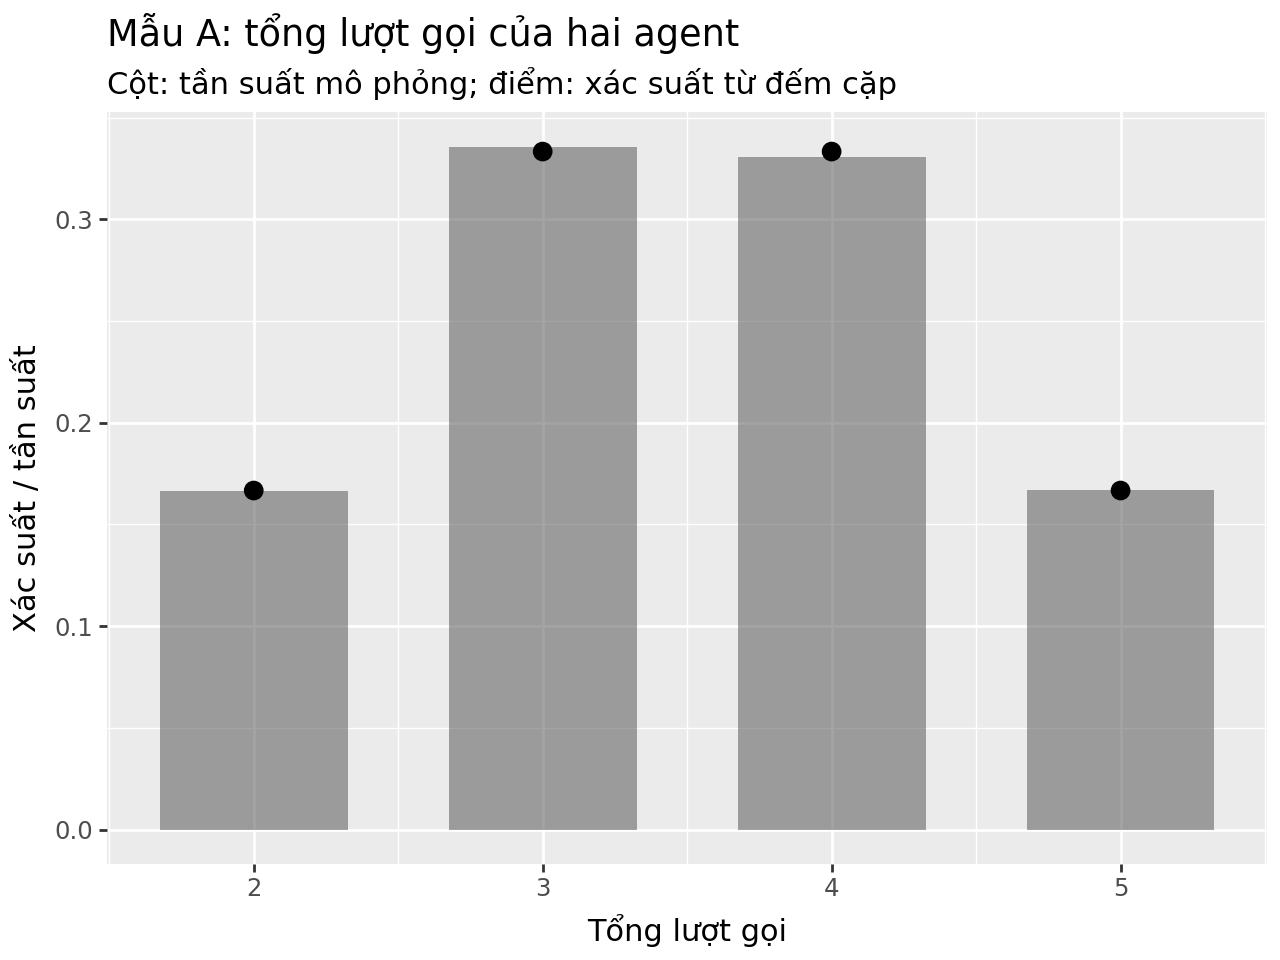

In [7]:
plot_a = (
    ggplot(table_a, aes(x="total_calls"))
    + geom_col(aes(y="frequency"), width=0.65, alpha=0.55)
    + geom_point(aes(y="theoretical_probability"), size=3)
    + scale_x_continuous(breaks=support.tolist())
    + labs(
        title="Mẫu A: tổng lượt gọi của hai agent",
        subtitle="Cột: tần suất mô phỏng; điểm: xác suất từ đếm cặp",
        x="Tổng lượt gọi", y="Xác suất / tần suất",
    )
)
display(plot_a)
plot_a.save(OUTPUT_DIR / "demo_pair_sums.png", width=7.5, height=4.5, dpi=140, verbose=False)


**Tự thử:** đổi số phiên, seed hoặc danh sách lựa chọn, rồi chạy lại từ ô cấu hình A. Với số phiên nhỏ, một tổng có xác suất dương có thể chưa xuất hiện. Tăng số phiên không sửa được một cơ chế sinh mẫu đã chọn sai.

## 3. Mẫu B — Tần suất của một tuyến xử lý

Bộ định tuyến thử nghiệm chọn đều mã từ 0 đến 11. Ta quan tâm mã **ít nhất bằng 9**. Dùng ba tiền tố dài 40, 400, 4.000 của cùng một dãy.

### Ô cấu hình B: thay mã và ngưỡng tại đây
`endpoint_max` là mã lớn nhất **được phép xuất hiện**; khi gọi `integers`, mã này cần được tính vào miền lấy mẫu.


In [8]:
DEMO_B = {
    "seed": 7,
    "endpoint_min": 0,
    "endpoint_max": 11,
    "threshold": 9,
    "sample_sizes": [40, 400, 4_000],
}
assert DEMO_B["endpoint_min"] <= DEMO_B["threshold"] <= DEMO_B["endpoint_max"]
assert all(isinstance(n, int) and n > 0 for n in DEMO_B["sample_sizes"])


### Bước B1. Tạo dãy, biến cố và xác suất lý thuyết

Đếm mã thỏa điều kiện từ **danh sách tất cả mã có thể chọn** để tính xác suất lý thuyết. Đếm `True` trong **dãy đã mô phỏng** để tính tần suất. Đây là hai phép đếm trên hai tập khác nhau.


In [9]:
rng_b = np.random.default_rng(DEMO_B["seed"])
endpoint_ids = rng_b.integers(
    DEMO_B["endpoint_min"], DEMO_B["endpoint_max"] + 1,
    size=max(DEMO_B["sample_sizes"]),
)
all_ids = np.arange(DEMO_B["endpoint_min"], DEMO_B["endpoint_max"] + 1)
favorable_ids = all_ids[all_ids >= DEMO_B["threshold"]]
p_theory = len(favorable_ids) / len(all_ids)
print("Các mã thuận lợi của VÍ DỤ MẪU:", favorable_ids)
print("Xác suất lý thuyết:", p_theory)
display(pd.DataFrame({
    "endpoint_id": endpoint_ids[:10],
    "event_happened": endpoint_ids[:10] >= DEMO_B["threshold"],
}))


Các mã thuận lợi của VÍ DỤ MẪU: [ 9 10 11]
Xác suất lý thuyết: 0.25


,endpoint_id,event_happened
0,11,True
1,7,False
2,8,False
3,10,True
4,6,False
5,9,True
6,10,True
7,2,False
8,0,False
9,3,False


### Bước B2. Một bảng theo cỡ mẫu

`endpoint_ids[:n]` lấy **n phần tử đầu**, không lấy phần tử ở chỉ số `n`. Với từng tiền tố, tạo dãy logic, đếm, chia đúng mẫu số và đối chiếu với lý thuyết.


In [10]:
rows_b = []
for n in DEMO_B["sample_sizes"]:
    flags = endpoint_ids[:n] >= DEMO_B["threshold"]
    event_count = int(flags.sum())
    frequency = float(flags.mean())
    rows_b.append({
        "n_trials": n,
        "event_count": event_count,
        "frequency": frequency,
        "theoretical_probability": p_theory,
        "absolute_error": abs(frequency - p_theory),
    })
    assert len(flags) == n
    assert np.isclose(frequency, event_count / n)

table_b = pd.DataFrame(rows_b)
display(table_b)


,n_trials,event_count,frequency,theoretical_probability,absolute_error
0,40,14,0.35000,0.25,0.10000
1,400,110,0.27500,0.25,0.02500
2,4000,1041,0.26025,0.25,0.01025


### Bước B3. Đọc hình và thay seed

Đường ngang là xác suất lý thuyết; các điểm là ba tần suất. Trục ngang dùng thang log chỉ để đặt các cỡ mẫu trên cùng hình, không làm thay đổi kết quả tính toán.

Ba tiền tố dùng chung dữ liệu nên ba ước lượng **không độc lập với nhau**. Mô hình giả thiết các **lượt chọn** độc lập. Đổi seed và quan sát lại; không chọn riêng seed có hình đẹp để trình bày như một quy luật.


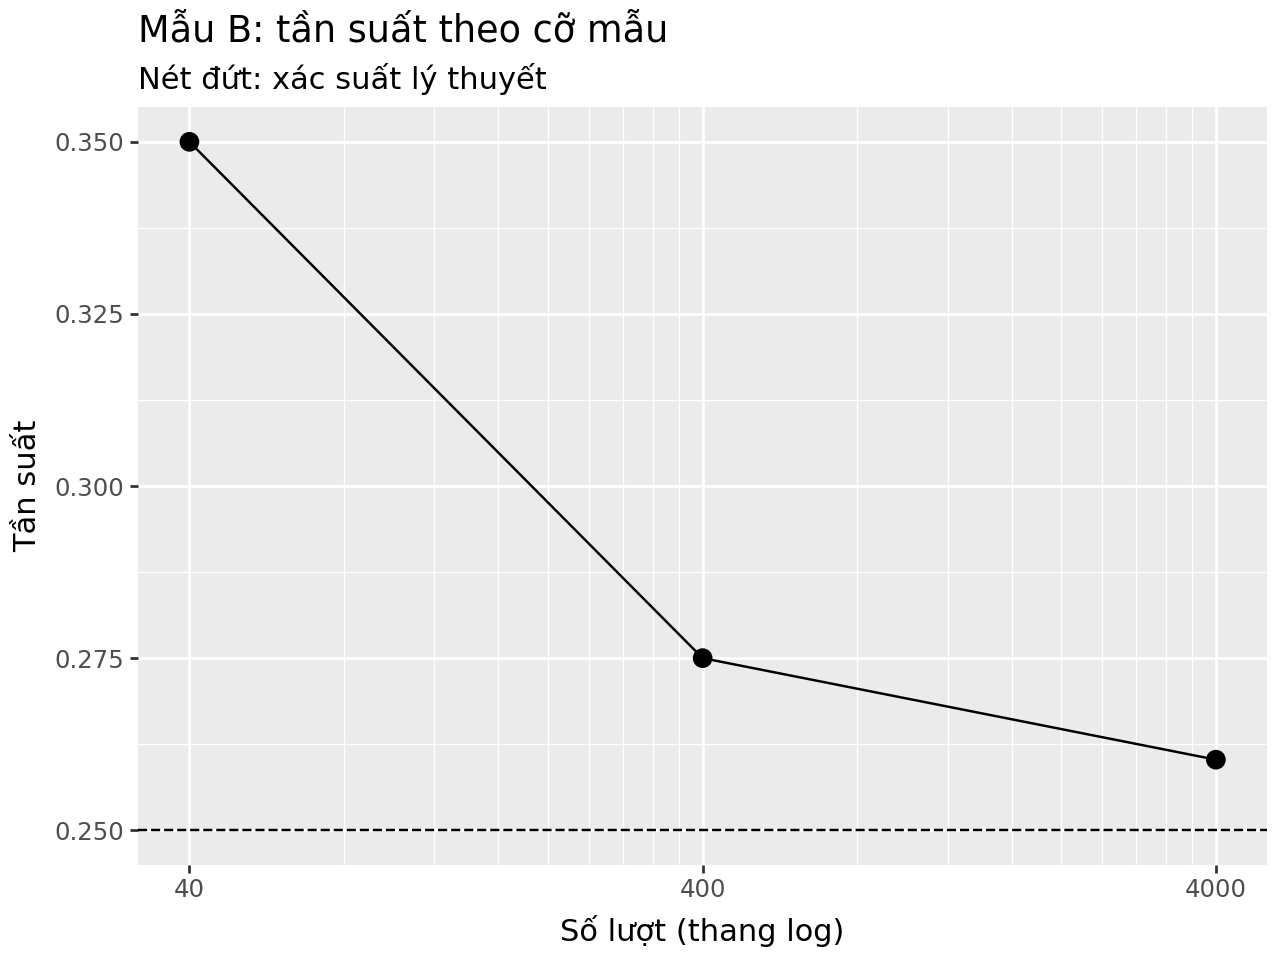

In [11]:
plot_b = (
    ggplot(table_b, aes(x="n_trials", y="frequency"))
    + geom_line() + geom_point(size=3)
    + geom_hline(yintercept=p_theory, linetype="dashed")
    + scale_x_log10(breaks=DEMO_B["sample_sizes"])
    + labs(title="Mẫu B: tần suất theo cỡ mẫu",
           subtitle="Nét đứt: xác suất lý thuyết", x="Số lượt (thang log)", y="Tần suất")
)
display(plot_b)
plot_b.save(OUTPUT_DIR / "demo_routing_frequency.png", width=7.5, height=4.5, dpi=140, verbose=False)


In [12]:
table_a.to_csv(OUTPUT_DIR / "demo_pair_sums.csv", index=False, encoding="utf-8-sig")
table_b.to_csv(OUTPUT_DIR / "demo_routing_summary.csv", index=False, encoding="utf-8-sig")
print("Đã lưu hai bảng CSV có dữ liệu và hai hình PNG tại:", OUTPUT_DIR.resolve())


Đã lưu hai bảng CSV có dữ liệu và hai hình PNG tại: /mnt/data/PS05_AI_Notebooks_27_28/ps05_27_28_outputs/template


## 4. Chuyển từ mẫu sang bài tập

Mở `PS05_AI_27_28_Student.ipynb`:

- Bài 27: đọc đề, trả lời câu a trước; sau đó tự điền đầu phải của `integers` và chiều cộng. Mẫu A minh họa cú pháp, không thay cho giải thích về không gian mẫu.
- Bài 28: đếm xác suất bằng tay trước; tự điền toán tử biến cố và xác suất lý thuyết. Mẫu B cho thấy cách lập bảng và đổi seed.

**Cần nộp:** notebook đã điền, có đầu ra, và các đoạn giải thích của chính mình. Không chỉ nộp notebook mẫu chưa sửa.


## Tài liệu tra cú pháp

Nội dung bài tập theo **PS05-AI, Bài 27–28**. Ví dụ học cú pháp được ghi riêng; không thay đổi yêu cầu của đề.

- [NumPy: Generator.integers](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.integers.html)
- [NumPy: Generator.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html)
- [plotnine: geom_col](https://plotnine.org/reference/geom_col.html)
- [VS Code: Jupyter Notebooks](https://code.visualstudio.com/docs/datascience/jupyter-notebooks)
